# Phase 2A | Real optogenetic neural-response prediction
**DANDI 000568 · XGBoost vs GRU vs TCN · held-out recording session**

**Scientific question:** Can we predict short-term mouse hippocampal population spiking from previous neural activity and *observed* future optical pulses? This is a **pilot conditional prediction study**, **not** epilepsy treatment, a personalized human digital twin, or proof of causal light effects.

**Inputs:** This notebook downloads two small `+ogen`, `no-raw-data` NWB files (about 73 MB combined) from DANDI 000568, published version `0.230705.1633`. It reads both `OptogeneticSeries` timestamps and `/units/spike_times` locally on Kaggle. No additional Kaggle input is required; **Internet ON**. Start on **CPU**.

**Evaluation design:** Train on session 9; test on session 12 (optional reverse test). Validation is later in the training session, with a time gap. **Both sessions come from one mouse**, so this does *not* measure cross-animal generalization. Optical values are uncalibrated codes in this audit and are **never** interpreted as watts or used as calibrated doses.

Source: https://dandiarchive.org/dandiset/000568 (DOI: 10.48324/dandi.000568/0.230705.1633)

## 1 — Settings and dependencies
Run all cells in order. `PILOT_MODE = True` keeps runtime modest. When the pipeline is verified, change to `False` to train on more examples and test both session directions.

In [1]:
import sys, subprocess, importlib.util
for package, module in [("requests","requests"),("h5py","h5py"),("numpy","numpy"),
                        ("pandas","pandas"),("matplotlib","matplotlib"),
                        ("scikit-learn","sklearn"),("xgboost","xgboost"),("torch","torch")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

from pathlib import Path
from datetime import datetime, timezone
import os, json, re, zipfile, warnings, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, h5py
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED=42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
PILOT_MODE = True
BIN_SEC = 0.020           # 20-ms bins, comparable to ~19-ms pulses
HISTORY_BINS = 50        # 1.0 second observed history
HORIZON_BINS = 5         # predict NEXT 100-ms population rate
EPOCHS = 8 if PILOT_MODE else 20
CAPS = {'train':8000,'val':2000,'test':4000} if PILOT_MODE else {'train':25000,'val':5000,'test':10000}
RUN_TWO_FOLDS = not PILOT_MODE   # True: train on each session in turn
BATCH_SIZE = 256
BASE = 'https://api.dandiarchive.org'
DANDISET = '000568'; VERSION = '0.230705.1633'
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT = ROOT/'phase2a_outputs'; CACHE = ROOT/'phase2a_nwb_cache'
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE,'PILOT_MODE:',PILOT_MODE,'Output:',OUT)
print('Important: we predict neural firing rate, NOT clinical seizures.')

Device: cpu PILOT_MODE: True Output: /kaggle/working/phase2a_outputs
Important: we predict neural firing rate, NOT clinical seizures.


## 2 — Locate and download ONLY the small NWB copies
Safety checks prevent accidental downloading of multi-gigabyte raw recordings. The version is pinned for reproducibility.

In [2]:
def api_json(url):
    response = requests.get(url, timeout=(15, 60), headers={'Accept':'application/json'})
    response.raise_for_status()
    return response.json()

assets=[]
url=f'{BASE}/api/dandisets/{DANDISET}/versions/{VERSION}/assets/'
while url:
    data=api_json(url); assets.extend(data['results']); url=data.get('next')
manifest=pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],'size_bytes':a['size']} for a in assets])
small=manifest[(manifest.path.str.endswith('.nwb')) &
               (manifest.path.str.contains('no-raw-data',regex=False)) &
               (manifest.path.str.contains('+ogen',regex=False)) &
               (manifest.size_bytes < 70_000_000)].sort_values('size_bytes')
print('Available small +ogen NWB files:',len(small))
print(small[['path','size_bytes']].to_string(index=False))
if len(small)<2: raise RuntimeError('Fewer than 2 small optogenetic NWB files in pinned manifest')
selected=small.head(2).copy()
if len(set(selected.path.str.extract(r'(sess\d+)')[0].dropna()))<2:
    raise RuntimeError('Selected files do not appear to describe two distinct sessions')

def download_small(row):
    if not str(row['path']).endswith('.nwb') or '+ogen' not in str(row['path']) or 'no-raw-data' not in str(row['path']):
        raise ValueError('Refusing an unexpected or raw-data asset')
    nbytes=int(row['size_bytes'])
    if nbytes > 70_000_000: raise ValueError('Safety cap exceeded: 70 MB per file')
    target=CACHE/str(row['path']).split('/')[-1]
    if target.exists() and target.stat().st_size==nbytes:
        print('Reusing:',target.name); return target
    url=f"{BASE}/api/assets/{row['asset_id']}/download/"
    temporary=target.with_suffix('.nwb.part')
    with requests.get(url, stream=True, timeout=(30,180)) as response:
        response.raise_for_status()
        with temporary.open('wb') as f:
            for block in response.iter_content(chunk_size=1024*1024):
                if block: f.write(block)
    if temporary.stat().st_size != nbytes:
        raise IOError('Asset download size mismatch')
    temporary.replace(target)
    print('Downloaded',target.name,'MB:',round(nbytes/1e6,2))
    return target

paths={}
for _, row in selected.iterrows():
    match=re.search(r'sess(\d+)', str(row['path']))
    if not match: raise ValueError('Cannot identify session in '+str(row['path']))
    paths['session_'+match.group(1)]=download_small(row)
print('Selected sessions:',sorted(paths))
if len(paths)!=2: raise RuntimeError('Expected two distinct sessions')

Available small +ogen NWB files: 2
                                                                                      path  size_bytes
sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb    28678484
 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb    44441669
Downloaded sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 28.68
Downloaded sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 44.44
Selected sessions: ['session_12', 'session_9']


## 3 — Recover pulse intervals and binned population spikes
We use the raw NWB `spike_times` table and positive segments of each `OptogeneticSeries`. The stimulation magnitude is **not** treated as physical power because encoded `watts` values in the source files look inconsistent. We use only binary *light occupancy* per optical site. Large raw `ElectricalSeries` is not needed for this pilot.

In [3]:
def as_text(x):
    return x.decode('utf-8','replace') if isinstance(x, bytes) else str(x)

def read_pulses(hf, label):
    root=hf.get('/stimulus/presentation')
    if root is None: raise ValueError('No /stimulus/presentation group')
    rows=[]
    for name,group in root.items():
        if not isinstance(group,h5py.Group) or not name.startswith('OptogeneticSeriesSite'):
            continue
        if 'data' not in group or 'timestamps' not in group:
            continue
        ts=np.asarray(group['timestamps'][:],dtype=np.float64)
        values=np.asarray(group['data'][:],dtype=np.float64).reshape(-1)
        if len(ts)!=len(values) or len(ts)<3 or not np.all(np.diff(ts)>=0):
            warnings.warn(f'{label}/{name} invalid timestamps or values'); continue
        flag=np.isfinite(values) & (values>0)
        starts=np.flatnonzero(flag & ~np.r_[False,flag[:-1]])
        ends=np.flatnonzero(~flag & np.r_[False,flag[:-1]])
        if flag[0]: starts=starts[1:]  # left-censored: do not invent its onset
        indices=np.searchsorted(ends,starts,side='right')
        valid=indices<len(ends)
        for i,j in zip(starts[valid],ends[indices[valid]]):
            if ts[j]<=ts[i]: continue
            rows.append({'session':label,'site':name.replace('OptogeneticSeries',''),
                         'onset_sec':float(ts[i]),'offset_sec':float(ts[j]),
                         'duration_sec':float(ts[j]-ts[i]),'raw_positive_code':float(values[i]),
                         'reported_unit':as_text(group['data'].attrs.get('unit','unknown'))})
    df=pd.DataFrame(rows)
    if df.empty: raise RuntimeError('No complete pulse ON/OFF intervals found in '+label)
    return df

def fractional_occupancy(onsets,offsets,n_bins,bin_sec=BIN_SEC):
    """Fraction of each time bin illuminated, clipped to [0,1]."""
    out=np.zeros(n_bins,dtype=np.float64)
    starts=np.asarray(onsets,dtype=np.float64); ends=np.asarray(offsets,dtype=np.float64)
    valid=np.isfinite(starts)&np.isfinite(ends)&(ends>starts)&(starts>=0)&(ends<(n_bins*bin_sec))
    starts=starts[valid]; ends=ends[valid]
    if not len(starts): return out.astype(np.float32)
    a=np.floor(starts/bin_sec).astype(np.int64)
    b=np.floor(np.nextafter(ends,-np.inf)/bin_sec).astype(np.int64)
    same=(a==b)
    np.add.at(out,a[same],(ends[same]-starts[same])/bin_sec)
    cross=~same
    np.add.at(out,a[cross],((a[cross]+1)*bin_sec-starts[cross])/bin_sec)
    np.add.at(out,b[cross],(ends[cross]-b[cross]*bin_sec)/bin_sec)
    # Add fully illuminated intermediate bins via range increments.
    diff=np.zeros(n_bins+1,dtype=np.float64)
    np.add.at(diff,a[cross]+1,1.0)
    np.add.at(diff,b[cross],-1.0)
    out+=np.cumsum(diff[:-1])
    return np.clip(out,0.0,1.0).astype(np.float32)

def read_session(label,file_path):
    with h5py.File(file_path,'r') as hf:
        if '/units/spike_times' not in hf or '/units/spike_times_index' not in hf:
            raise RuntimeError('Missing sorted unit spike times: '+label)
        spikes=np.asarray(hf['/units/spike_times'][:],dtype=np.float64)
        n_units=len(hf['/units/spike_times_index'])
        if not n_units or not len(spikes): raise RuntimeError('No neural spikes in '+label)
        spikes=spikes[np.isfinite(spikes)&(spikes>=0)]
        events=read_pulses(hf,label)
    if events.onset_sec.max()>spikes.max() or events.onset_sec.min()<spikes.min():
        raise RuntimeError('Light pulses outside spike time span: check clock alignment')
    n_bins=int(np.ceil(max(spikes.max(),float(events.offset_sec.max()))/BIN_SEC))+10
    indices=np.floor(spikes/BIN_SEC).astype(np.int64)
    counts=np.bincount(indices,minlength=n_bins).astype(np.float32)
    rate=counts/(n_units*BIN_SEC) # average spikes/s per sorted unit
    return {'session':label,'spikes':spikes,'n_units':n_units,'n_bins':n_bins,'rate':rate,'events':events}

sessions={label:read_session(label,path) for label,path in sorted(paths.items())}
SITES=sorted(set(pd.concat([s['events'] for s in sessions.values()],ignore_index=True).site))
for label,s in sessions.items():
    s['light']=np.column_stack([
        fractional_occupancy(s['events'].loc[s['events'].site==site,'onset_sec'],
                             s['events'].loc[s['events'].site==site,'offset_sec'],s['n_bins'])
        for site in SITES]).astype(np.float32)
    # History features: log(1+rate), site-specific optical occupancy, any-light occupancy.
    s['history_features']=np.column_stack([np.log1p(s['rate']),s['light'],s['light'].max(axis=1)]).astype(np.float32)
    print(label,': sorted units',s['n_units'],', spikes',len(s['spikes']),
          ', pulses',len(s['events']),', recording seconds',round(s['n_bins']*BIN_SEC))
all_events=pd.concat([s['events'] for s in sessions.values()],ignore_index=True)
all_events.to_csv(OUT/'pulse_events_from_real_NWB.csv',index=False)
print('Optical sites:',SITES)
print('Raw optical codes by session (DO NOT interpret as watts):')
print(all_events.groupby('session').raw_positive_code.unique().apply(lambda x:list(x)[:10]).to_string())

session_12 : sorted units 47 , spikes 1800735 , pulses 50309 , recording seconds 14810
session_9 : sorted units 57 , spikes 2259343 , pulses 42088 , recording seconds 17920
Optical sites: ['Site3', 'Site4', 'Site5', 'Site6', 'Site7', 'Site8']
Raw optical codes by session (DO NOT interpret as watts):
session
session_12    [62711.0, 62623.0, 62687.0, 62911.0, 63599.0]
session_9                                            [19.0]


## 4 — Construct leakage-controlled supervised examples
Each example contains **1 second of observed neural + light history** and the **recorded light schedule for the next 100 ms**. The target is the **observed population firing rate in that same future 100 ms**. This is *conditional association*, not proof of a causal stimulation effect. We balance action/no-action examples *within the stimulation epoch* and enforce spacing between sampled anchors; it is still one mouse.

**No future neural measurements enter model inputs.** No mixing of session 9 and session 12 in train/test. Validation uses a chronological later portion of the training session, with a 20-second gap.

In [4]:
def make_splits(s,kind,cut_fraction=0.75):
    n=s['n_bins']; light=s['light']
    earliest=int(np.floor(s['events'].onset_sec.min()/BIN_SEC))
    latest=int(np.ceil(s['events'].offset_sec.max()/BIN_SEC))
    lo=max(HISTORY_BINS,earliest-int(30/BIN_SEC))
    hi=min(n-HORIZON_BINS-1,latest+int(30/BIN_SEC))
    if not (hi-lo > 100): raise ValueError('Stimulation epoch too short')
    if kind=='train_val':
        cut=int(lo+(hi-lo)*cut_fraction)
        gap=int(20/BIN_SEC) + HISTORY_BINS + HORIZON_BINS
        return (lo,cut-gap),(cut+gap,hi)
    return (lo,hi)

def pick_anchors(s,lo_hi,limit,seed):
    lo,hi=map(int,lo_hi)
    if hi<=lo+HISTORY_BINS: raise ValueError('Not enough time for sampled windows')
    mask=(s['light'].max(axis=1)>0).astype(np.int32)
    c=np.r_[0,np.cumsum(mask.astype(np.int64))]
    candidates=np.arange(lo,hi+1,dtype=np.int64)
    future_has_light=(c[candidates+HORIZON_BINS]-c[candidates])>0
    positives=candidates[future_has_light]
    negatives=candidates[~future_has_light]
    rng=np.random.default_rng(seed); rng.shuffle(positives); rng.shuffle(negatives)
    blocked=np.zeros(s['n_bins'],dtype=bool)
    selected=[]
    spacing=HORIZON_BINS+1
    target_each=limit//2
    def collect(pool,n_wanted):
        added=0
        for ix in pool:
            if added>=n_wanted: break
            if blocked[ix]: continue
            selected.append(int(ix)); added+=1
            blocked[max(0,ix-spacing):min(len(blocked),ix+spacing+1)]=True
        return added
    npos=collect(positives,target_each)
    nneg=collect(negatives,limit-npos)
    if len(selected)<limit:
        collect(positives,limit-len(selected))
    if len(selected)<limit:
        collect(negatives,limit-len(selected))
    return np.asarray(sorted(selected),dtype=np.int64)

def examples_at(s,anchors):
    a=np.asarray(anchors,dtype=np.int64)
    if not len(a): raise RuntimeError('No anchors selected')
    history_idxs=a[:,None]+np.arange(-HISTORY_BINS,0)[None,:]
    X=s['history_features'][history_idxs]
    site_light=s['light']
    actprefix=np.vstack([np.zeros((1,site_light.shape[1]),dtype=np.float64),
                         np.cumsum(site_light,dtype=np.float64,axis=0)])
    action=((actprefix[a+HORIZON_BINS]-actprefix[a])/HORIZON_BINS).astype(np.float32)
    rprefix=np.r_[0,np.cumsum(s['rate'],dtype=np.float64)]
    target=((rprefix[a+HORIZON_BINS]-rprefix[a])/HORIZON_BINS).astype(np.float32)
    prev=((rprefix[a]-rprefix[a-HORIZON_BINS])/HORIZON_BINS).astype(np.float32)
    has_action=(action.max(axis=1)>0)
    return {'X':X,'actions':action,'y':target,'persistence':prev,
            'light_future':has_action,'anchors':a,'session':s['session']}

def prepare_fold(train_s,test_s,seed=SEED):
    (train_rng,val_rng)=make_splits(train_s,'train_val')
    test_rng=make_splits(test_s,'test')
    a_train=pick_anchors(train_s,train_rng,CAPS['train'],seed)
    a_val=pick_anchors(train_s,val_rng,CAPS['val'],seed+1)
    a_test=pick_anchors(test_s,test_rng,CAPS['test'],seed+2)
    tr,va,te=examples_at(train_s,a_train),examples_at(train_s,a_val),examples_at(test_s,a_test)
    for name,e in [('train',tr),('val',va),('test',te)]:
        print(name,e['session'],len(e['y']),'light-active fraction',round(e['light_future'].mean(),3),
              'target mean Hz',round(float(np.mean(e['y'])),3))
    assert train_s['session']==tr['session']==va['session'] and train_s['session']!=te['session']
    assert tr['anchors'].max()+HISTORY_BINS+HORIZON_BINS < va['anchors'].min()
    return tr,va,te

labels=sorted(sessions)
# Run session 9 as train and 12 as test first, if both are present.
first= 'session_9' if 'session_9' in sessions else labels[0]
second='session_12' if 'session_12' in sessions else [x for x in labels if x!=first][0]
FOLDS=[(first,second)] + ([(second,first)] if RUN_TWO_FOLDS else [])
print('Training / held-out-session evaluation:',FOLDS)

Training / held-out-session evaluation: [('session_9', 'session_12')]


## 5 — Baselines and Deep Learning models
Our baselines are **persistence**, **XGBoost neural-only**, and **XGBoost with observed optical action information**. Neural models are a compact **GRU** and **TCN**. Every feature normalization parameter is estimated on the training examples only. Targets are log-transformed to reduce sensitivity to extreme spike-count windows.

In [5]:
def xgb_features(ex,allow_light=True):
    rate=np.expm1(np.maximum(ex['X'][:,:,0],0))  # restore per-unit Hz from log(1+rate)
    pieces=[rate[:,-HORIZON_BINS:].mean(axis=1),
            rate[:,-10:].mean(axis=1),rate.mean(axis=1),
            rate.std(axis=1),rate.max(axis=1),
            (rate[:,-10:].mean(axis=1)-rate[:,:10].mean(axis=1))]
    if allow_light:
        # site light history and recorded light plan for the prediction horizon
        nsites=ex['actions'].shape[1]
        history=ex['X'][:,:,1:1+nsites]
        for k in range(nsites):
            pieces.extend([history[:,:,k].mean(axis=1),history[:,-5:,k].mean(axis=1),ex['actions'][:,k]])
    return np.column_stack(pieces).astype(np.float32)

def transforms_from_train(train):
    xm=train['X'].mean(axis=(0,1)); xs=train['X'].std(axis=(0,1)).clip(1e-3)
    am=train['actions'].mean(axis=0); ast=train['actions'].std(axis=0).clip(1e-3)
    ly=np.log1p(np.maximum(0,train['y']))
    ym=float(ly.mean()); ys=max(float(ly.std()),0.01)
    return {'xm':xm,'xs':xs,'am':am,'ast':ast,'ym':ym,'ys':ys}

def preprocess_dl(ex,sc):
    X=np.clip((ex['X']-sc['xm'])/sc['xs'],-8,8).astype(np.float32)
    A=np.clip((ex['actions']-sc['am'])/sc['ast'],-8,8).astype(np.float32)
    Y=((np.log1p(np.maximum(0,ex['y']))-sc['ym'])/sc['ys']).astype(np.float32)
    return X,A,Y

class GRUNet(nn.Module):
    def __init__(self,n_features,n_actions):
        super().__init__()
        self.rnn=nn.GRU(input_size=n_features,hidden_size=32,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32+n_actions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        _, h=self.rnn(x)
        return self.head(torch.cat((h[-1],a),dim=1)).squeeze(1)

class TCNNet(nn.Module):
    def __init__(self,n_features,n_actions):
        super().__init__()
        layers=[]; nin=n_features
        for dil in (1,2,4,8):
            layers += [nn.Conv1d(nin,24,kernel_size=3,dilation=dil,padding=2*dil),nn.ReLU()]
            nin=24
        self.encoder=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.Linear(24+n_actions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        # CNN sees observed history only; padding to the right is cropped at each layer.
        z=x.transpose(1,2)
        for layer in self.encoder:
            if isinstance(layer,nn.Conv1d):
                z=layer(z)[:,:,:x.shape[1]]
            else: z=layer(z)
        h=z[:,:,-1]
        return self.head(torch.cat((h,a),dim=1)).squeeze(1)

def train_dl(cls,train,val,sc,seed=SEED):
    torch.manual_seed(seed)
    X,A,Y=preprocess_dl(train,sc)
    vX,vA,vY=preprocess_dl(val,sc)
    model=cls(X.shape[-1],A.shape[-1]).to(DEVICE)
    ds=TensorDataset(torch.from_numpy(X),torch.from_numpy(A),torch.from_numpy(Y))
    dl=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    optimizer=torch.optim.Adam(model.parameters(),lr=0.002,weight_decay=1e-4)
    loss_fn=nn.SmoothL1Loss()
    vx=torch.from_numpy(vX).to(DEVICE); va=torch.from_numpy(vA).to(DEVICE); vy=torch.from_numpy(vY).to(DEVICE)
    best=float('inf'); best_state=None; bad=0; trace=[]
    for epoch in range(EPOCHS):
        model.train(); total=0; count=0
        for hx,ha,hy in dl:
            hx=hx.to(DEVICE);ha=ha.to(DEVICE);hy=hy.to(DEVICE)
            optimizer.zero_grad(); pred=model(hx,ha);loss=loss_fn(pred,hy)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total+=float(loss.item())*len(hy);count+=len(hy)
        model.eval()
        with torch.no_grad():
            losses=[]
            for st in range(0,len(vY),BATCH_SIZE):
                pred=model(vx[st:st+BATCH_SIZE],va[st:st+BATCH_SIZE])
                losses.append((float(loss_fn(pred,vy[st:st+BATCH_SIZE]).item()),len(pred)))
            vl=sum(a*b for a,b in losses)/max(sum(b for a,b in losses),1)
        trainloss=total/max(count,1)
        trace.append({'epoch':epoch+1,'train_loss':trainloss,'val_loss':vl})
        print(cls.__name__,'epoch',epoch+1,'train',round(trainloss,4),'val',round(vl,4))
        if vl<best-1e-4: best=vl;bad=0;best_state=copy.deepcopy(model.state_dict())
        else:
            bad+=1
            if bad>=3: break
    if best_state is not None: model.load_state_dict(best_state)
    return model,pd.DataFrame(trace)

@torch.no_grad()
def predict_dl(model,ex,sc):
    model.eval()
    X,A,_=preprocess_dl(ex,sc)
    preds=[]
    for i in range(0,len(X),BATCH_SIZE):
        yp=model(torch.from_numpy(X[i:i+BATCH_SIZE]).to(DEVICE),
                 torch.from_numpy(A[i:i+BATCH_SIZE]).to(DEVICE))
        preds.append(yp.cpu().numpy())
    z=np.concatenate(preds)*sc['ys']+sc['ym']
    return np.maximum(0,np.expm1(np.clip(z,-4,8)))

def metrics(y,yp):
    return {'MAE_Hz':float(mean_absolute_error(y,yp)),
            'RMSE_Hz':float(np.sqrt(mean_squared_error(y,yp))),
            'R2':float(r2_score(y,yp))}

## 6 — Train, evaluate, and save real results
The models are trained on **one mouse's one session** and tested on a **different session from the same mouse**. Prediction quality may be poor. The persistence and no-light baselines are essential and **should not be omitted**.

In [6]:
ALL_METRICS=[]; ALL_PREDS=[]; ALL_TRACES=[]; SAMPLE_AUDITS=[]
for fold,(train_label,test_label) in enumerate(FOLDS,1):
    print('\n'+'='*20, 'FOLD',fold,train_label,'->',test_label,'='*20)
    train,val,test=prepare_fold(sessions[train_label],sessions[test_label],seed=SEED+fold*100)
    for stage,ex in [('train',train),('val',val),('test',test)]:
        SAMPLE_AUDITS.append({'fold':fold,'split':stage,'session':ex['session'],
            'n_examples':len(ex['y']),'light_future_fraction':float(ex['light_future'].mean()),
            'start_sec':float(ex['anchors'].min()*BIN_SEC),'end_sec':float(ex['anchors'].max()*BIN_SEC)})
    predictions={'Persistence':test['persistence']}
    for allow,name in [(False,'XGBoost_neural_only'),(True,'XGBoost_with_observed_light')]:
        model=XGBRegressor(n_estimators=130 if PILOT_MODE else 250,max_depth=3,
            learning_rate=0.06,subsample=0.9,colsample_bytree=0.9,
            objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=SEED)
        model.fit(xgb_features(train,allow),np.log1p(train['y']))
        predictions[name]=np.maximum(0,np.expm1(np.clip(model.predict(xgb_features(test,allow)),-4,8)))
        model.save_model(str(OUT/f'xgb_fold{fold}_{"light" if allow else "neural_only"}.json'))
    sc=transforms_from_train(train)
    (OUT/f'scalers_fold{fold}.json').write_text(json.dumps({k:np.asarray(v).tolist() for k,v in sc.items()},indent=2))
    for cls in (GRUNet,TCNNet):
        model,trace=train_dl(cls,train,val,sc,seed=SEED+fold)
        name=cls.__name__.replace('Net','')
        predictions[name]=predict_dl(model,test,sc)
        trace['model']=name;trace['fold']=fold;ALL_TRACES.append(trace)
        torch.save({'model':name,'state_dict':model.cpu().state_dict(),
                   'input_features':int(train['X'].shape[-1]),'n_actions':int(train['actions'].shape[-1]),
                   'trained_session':train_label},OUT/f'{name}_fold{fold}.pt')
    pdf=pd.DataFrame({'fold':fold,'heldout_session':test['session'],
                      'time_sec':test['anchors']*BIN_SEC,
                      'true_future_rate_Hz':test['y'],
                      'light_in_future':test['light_future']})
    for name,pred in predictions.items():
        pred=np.asarray(pred,dtype=float)
        pdf[name+'_pred_Hz']=pred
        for group,mask in [('ALL',np.ones(len(pred),dtype=bool)),
                           ('LIGHT_FUTURE',test['light_future']),
                           ('NO_LIGHT_FUTURE',~test['light_future'])]:
            if mask.sum()<5: continue
            ALL_METRICS.append({'fold':fold,'train_session':train_label,'test_session':test_label,
                                'model':name,'group':group,'n_windows':int(mask.sum()),
                                **metrics(test['y'][mask],pred[mask])})
    ALL_PREDS.append(pdf)
    print('\nHeld-out session results (lower MAE is better):')
    print(pd.DataFrame(ALL_METRICS).query('fold==@fold and group=="ALL"')[['model','n_windows','MAE_Hz','RMSE_Hz','R2']].sort_values('MAE_Hz').to_string(index=False))

results=pd.DataFrame(ALL_METRICS)
predictions=pd.concat(ALL_PREDS,ignore_index=True)
sample_audit=pd.DataFrame(SAMPLE_AUDITS)
results.to_csv(OUT/'heldout_session_metrics.csv',index=False)
predictions.to_csv(OUT/'heldout_session_predictions.csv',index=False)
sample_audit.to_csv(OUT/'sample_split_audit.csv',index=False)
if ALL_TRACES: pd.concat(ALL_TRACES,ignore_index=True).to_csv(OUT/'dl_training_curves.csv',index=False)


==================== FOLD 1 session_9 -> session_12 ====================
train session_9 8000 light-active fraction 0.5 target mean Hz 2.671
val session_9 2000 light-active fraction 0.5 target mean Hz 2.8
test session_12 4000 light-active fraction 0.5 target mean Hz 2.946
GRUNet epoch 1 train 0.3694 val 0.2684
GRUNet epoch 2 train 0.2926 val 0.2545
GRUNet epoch 3 train 0.2882 val 0.2559
GRUNet epoch 4 train 0.2853 val 0.2501
GRUNet epoch 5 train 0.2854 val 0.2562
GRUNet epoch 6 train 0.2838 val 0.2511
GRUNet epoch 7 train 0.2822 val 0.2499
GRUNet epoch 8 train 0.2812 val 0.2484
TCNNet epoch 1 train 0.3845 val 0.2605
TCNNet epoch 2 train 0.3023 val 0.2602
TCNNet epoch 3 train 0.2928 val 0.2577
TCNNet epoch 4 train 0.2866 val 0.253
TCNNet epoch 5 train 0.2833 val 0.2546
TCNNet epoch 6 train 0.2838 val 0.2538
TCNNet epoch 7 train 0.2817 val 0.2578

Held-out session results (lower MAE is better):
                      model  n_windows   MAE_Hz  RMSE_Hz        R2
                        GR

## 7 — Actual experiment figures (generated from real NWB files)
These figures summarize **recorded-data prediction error** and help diagnose modeling quality. They are NOT therapeutic outcomes or proof of stimulation efficacy.

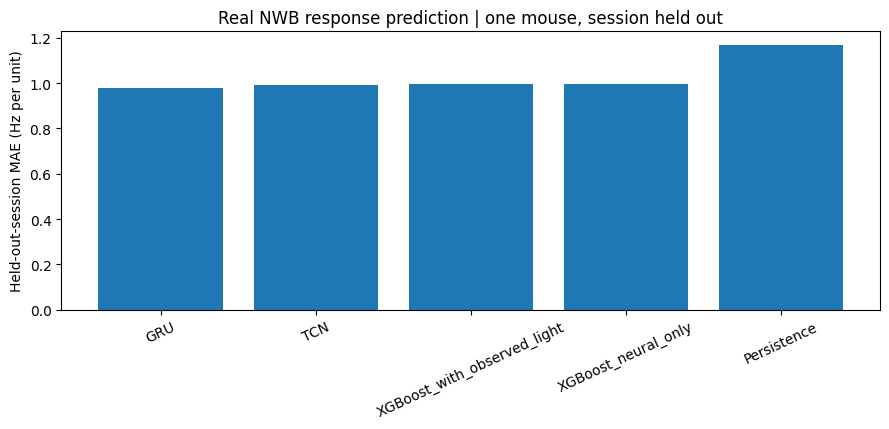

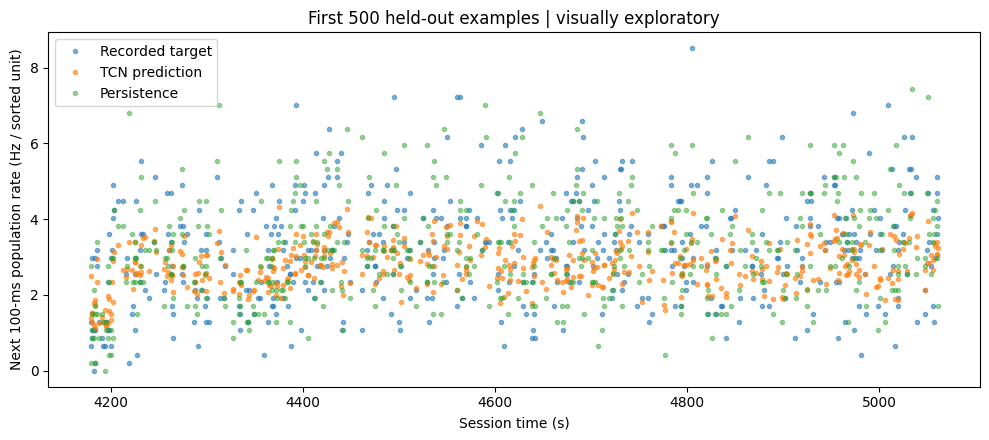


DONE! Download: /kaggle/working/phase2a_real_neural_prediction_results.zip
Upload the ZIP here for scientific review of model performance.


In [7]:
firstfold=results[(results.fold==1)&(results.group=='ALL')].sort_values('MAE_Hz')
fig,ax=plt.subplots(figsize=(9,4.4))
ax.bar(firstfold.model,firstfold.MAE_Hz)
ax.set_ylabel('Held-out-session MAE (Hz per unit)')
ax.set_title('Real NWB response prediction | one mouse, session held out')
ax.tick_params(axis='x',rotation=25)
plt.tight_layout();fig.savefig(OUT/'real_heldout_model_MAE.png',dpi=170);plt.show()

pp=predictions[predictions.fold==1].sort_values('time_sec').head(500)
fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(pp.time_sec,pp.true_future_rate_Hz,'.',alpha=0.55,label='Recorded target')
ax.plot(pp.time_sec,pp.TCN_pred_Hz,'.',alpha=0.60,label='TCN prediction')
ax.plot(pp.time_sec,pp.Persistence_pred_Hz,'.',alpha=0.45,label='Persistence')
ax.set_xlabel('Session time (s)');ax.set_ylabel('Next 100-ms population rate (Hz / sorted unit)')
ax.set_title('First 500 held-out examples | visually exploratory')
ax.legend();plt.tight_layout();fig.savefig(OUT/'real_heldout_predictions.png',dpi=170);plt.show()

report={'dataset':'DANDI 000568','version':VERSION,'date_utc':datetime.now(timezone.utc).isoformat(),
  'study_type':'mouse hippocampus short-horizon conditional prediction',
  'sessions':{k:{'n_units':int(v['n_units']),'n_spikes':int(len(v['spikes'])),
                 'n_pulses':int(len(v['events'])),'n_recording_bins':int(v['n_bins'])} for k,v in sessions.items()},
  'light_sites':SITES,'bin_sec':BIN_SEC,'observed_history_sec':HISTORY_BINS*BIN_SEC,
  'future_horizon_sec':HORIZON_BINS*BIN_SEC,'target':'future population firing rate (Hz per sorted unit)',
  'selected_future_light_schedule':'observed optical ON fractions; not known causal effect',
  'folds':FOLDS,'pilot_mode':PILOT_MODE,
  'limitations':['Both sessions are from the same mouse; no cross-animal personalization test.',
     'Pulse value units are not calibrated; do not interpret numerical codes as watts.',
     'Light pulses are clustered and correlated between recording sites.',
     'Prediction is conditional, not evidence of causal efficacy.',
     'Event time overlap is not enough to prove millisecond-accurate clock synchronization.',
     'No human patient data and no epilepsy/seizure suppression outcomes.',
     'Optical features from the recorded future are an offline known action plan, not autonomous control.']}
(OUT/'run_report.json').write_text(json.dumps(report,indent=2))
archive=ROOT/'phase2a_real_neural_prediction_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in OUT.iterdir():
        if f.is_file(): z.write(f,arcname=f.name)
print('\nDONE! Download:',archive)
print('Upload the ZIP here for scientific review of model performance.')

## 8 — Decision rules after the Kaggle run

1. **Compare to persistence first.** If GRU or TCN cannot beat persistence and neural-only XGBoost on the held-out session, pause architecture work and audit labels, signal quality, and event timing.
2. **Check whether including light actually helps.** Improvement alone does not prove a causal effect; light pulses may correlate with the experimental schedule or brain state.
3. **Confirm timestamp quality and optical calibration** before optimizing actual stimulation dose.
4. **Do not claim generalization across mice or epilepsy.** Only one animal is represented in these two `+ogen` sessions. Expand the biological cohort or narrow the manuscript claim before targeting a journal.
5. If pilot results are reasonable, enable `PILOT_MODE=False` to run both held-out-session directions with more examples and stronger statistical analysis.

**Please upload:** `phase2a_real_neural_prediction_results.zip` after a successful Kaggle Run All. This ZIP contains real-data metrics, predictions, model weights, figures and audit summaries but excludes the larger downloaded NWB files.